# Phân tích cảm xúc đánh giá sản phẩm thương mại điện tử (Tiki/Shopee)


In [8]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter


sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.figsize'] = (14, 6)

CURRENT_DIR = Path.cwd()
PROJECT_ROOT = CURRENT_DIR.parent 

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "reviews_clean.csv"
df = pd.read_csv(DATA_PATH)

## 1. Biểu đồ 1: Phân bố số lượng đánh giá theo số sao (1–5 sao)
Biểu đồ này giúp thống kê thói quen đánh giá của khách hàng trên sàn thương mại điện tử.

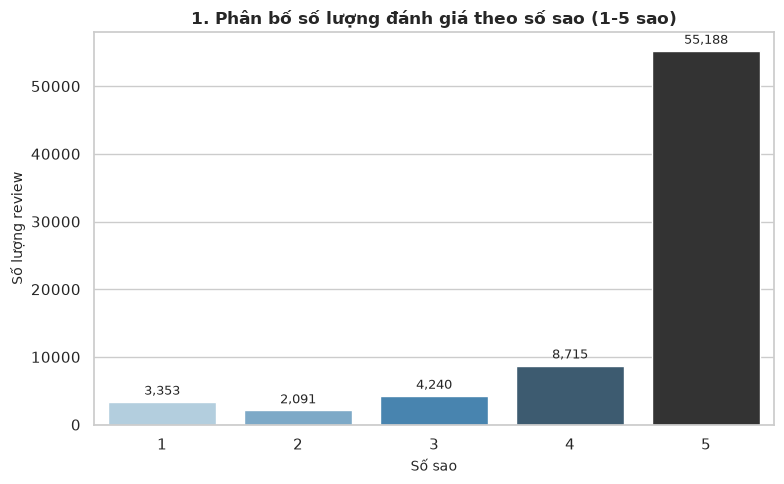

In [12]:
plt.figure(figsize=(8, 5))
ax = sns.countplot(x='rating', data=df, hue='rating', palette='Blues_d', legend=False)
plt.title('1. Phân bố số lượng đánh giá theo số sao (1-5 sao)', fontsize=12, fontweight='bold')
plt.xlabel('Số sao', fontsize=10)
plt.ylabel('Số lượng review', fontsize=10)

# Hiển thị số lượng cụ thể trên đầu mỗi cột
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()

## 2. Biểu đồ 2: Phân bố tỷ lệ nhãn cảm xúc (Positive, Negative, Neutral)
Biểu đồ này kiểm tra sự phân phối và tình trạng mất cân bằng dữ liệu giữa các nhóm cảm xúc sau khi được quy đổi từ số sao.

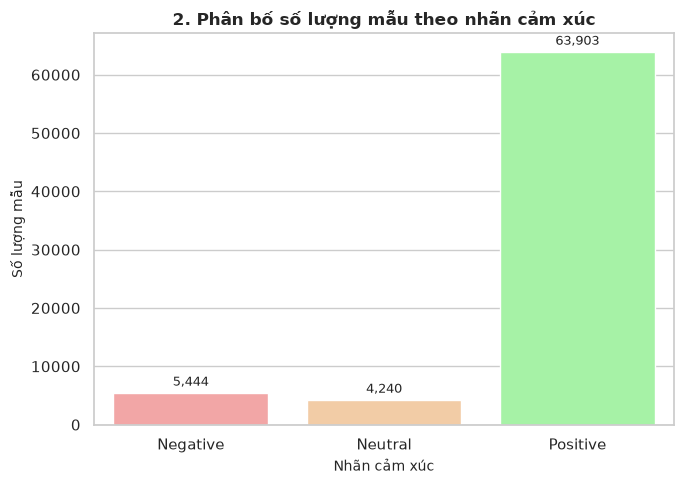

In [ ]:
plt.figure(figsize=(7, 5))
sentiment_counts = df['sentiment'].value_counts().reindex(['Negative', 'Neutral', 'Positive'])
ax = sns.barplot(x=sentiment_counts.index, y=sentiment_counts.values, palette=['#ff9999', '#ffcc99', '#99ff99'], legend=False, hue=sentiment_counts.index)
plt.title('2. Phân bố số lượng mẫu theo nhãn cảm xúc', fontsize=12, fontweight='bold')
plt.xlabel('Nhãn cảm xúc', fontsize=10)
plt.ylabel('Số lượng mẫu', fontsize=10)

for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()

## 3. Biểu đồ 3: Phân bố độ dài câu bình luận theo nhóm cảm xúc
Biểu đồ này giúp so sánh xem khách hàng khi đánh giá tiêu cực (chê) hay tích cực (khen) thường viết dài dòng hay ngắn gọn hơn (tính theo số từ trong mỗi review).

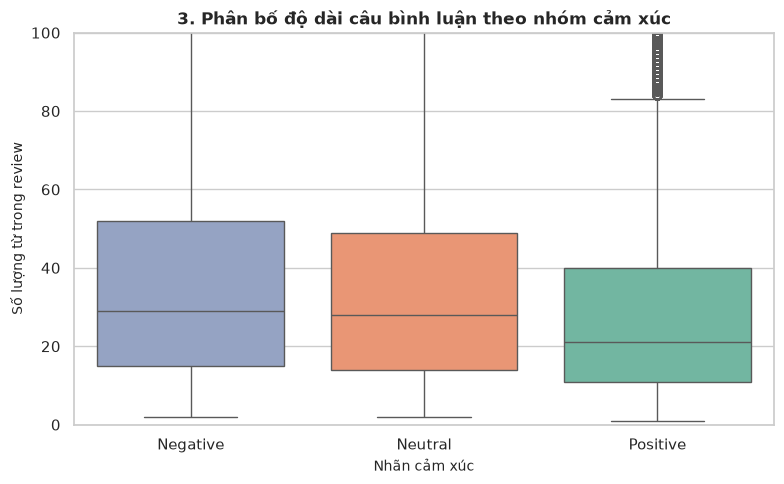

In [14]:
df['word_count'] = df['text'].apply(lambda x: len(str(x).split()))

plt.figure(figsize=(8, 5))
sns.boxplot(x='sentiment', y='word_count', data=df, order=['Negative', 'Neutral', 'Positive'], palette='Set2',legend=False, hue="sentiment")
plt.title('3. Phân bố độ dài câu bình luận theo nhóm cảm xúc', fontsize=12, fontweight='bold')
plt.xlabel('Nhãn cảm xúc', fontsize=10)
plt.ylabel('Số lượng từ trong review', fontsize=10)
plt.ylim(0, 100)  # Giới hạn trục y để tập trung vào phần lớn dữ liệu
plt.tight_layout()
plt.show()

## 4. Biểu đồ 4: Top 10 từ khóa phổ biến (Dựa trên cột `text_clean`)
Biểu đồ này thể hiện các từ xuất hiện nhiều nhất sau khi đã loại bỏ từ dừng, giúp thấy được các từ ngữ mang sắc thái khen/chê đặc trưng của người mua hàng.

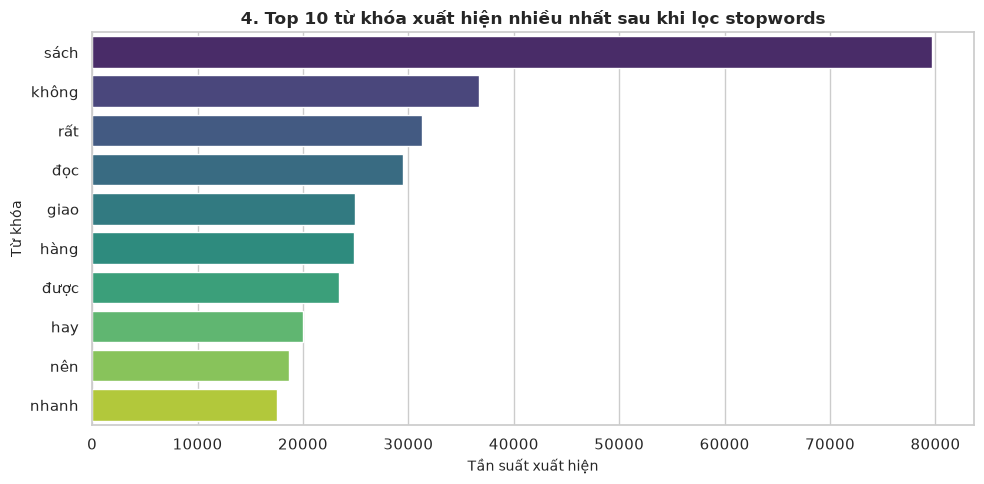

In [16]:
all_words = ' '.join(df['text_clean'].dropna()).split()
word_counts = Counter(all_words).most_common(10)
words, counts = zip(*word_counts)

plt.figure(figsize=(10, 5))
sns.barplot(x=list(counts), y=list(words), palette='viridis', legend=False, hue=list(words))
plt.title('4. Top 10 từ khóa xuất hiện nhiều nhất sau khi lọc stopwords', fontsize=12, fontweight='bold')
plt.xlabel('Tần suất xuất hiện', fontsize=10)
plt.ylabel('Từ khóa', fontsize=10)
plt.tight_layout()
plt.show()